# Laboratorio 2B · LLM-Modulo en práctica

La gerente de operaciones de **MantenIA** ya vio funcionar el planificador del Laboratorio 2A y hace la pregunta de moda: *«¿Y si les pedimos los planes a un modelo de lenguaje? Entiende las órdenes tal como las escribimos, sin PDDL»*. Es la pregunta del club de lectura de esta sesión: **¿pueden planificar los LLMs?**

Kambhampati y sus colegas (2024) responden con una posición en dos mitades. Por sí solos, los LLMs no generan planes ejecutables de forma confiable ni verifican bien sus propios planes. Pero son muy útiles como **generadores de candidatos** y como **traductores** si se combinan con **verificadores externos** basados en modelos, en lo que llaman el marco **LLM-Modulo**. En ese marco la garantía no la da el LLM: la dan los críticos que revisan lo que propone.

En este laboratorio usted pondrá esa posición a prueba con las órdenes de MantenIA del Laboratorio 2A. Comparará tres formas de usar un LLM, siempre con el mismo validador como juez:

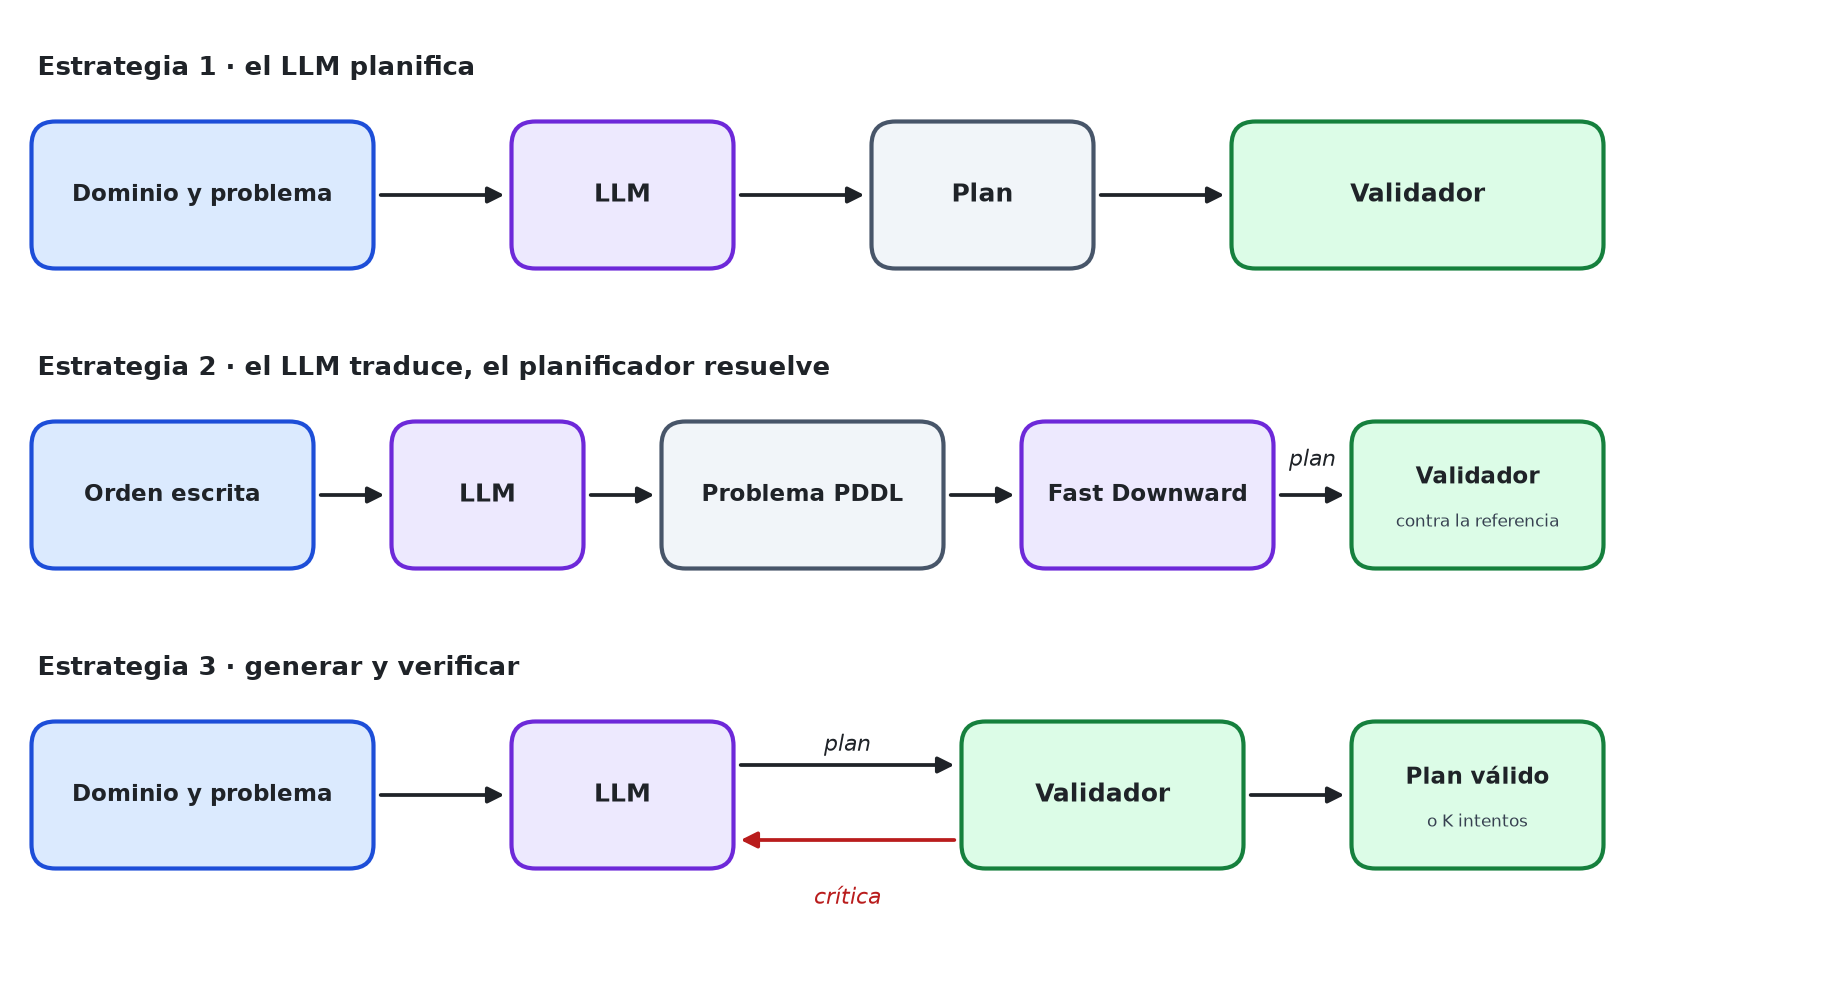

En este laboratorio usted:
* Reproducirá, sin gastar llamadas, el ciclo LLM-Modulo con un plan fijo: un plan con un error, el mensaje del validador, la crítica y el plan corregido.
* Comprobará que **el validador verifica contra el modelo PDDL**: si el modelo está mal traducido, certifica lo incorrecto.
* Comparará las tres estrategias de la figura: el LLM **planifica**, el LLM **traduce** a PDDL y el ciclo **generar-verificar**.
* Medirá validez, iteraciones, tokens, tiempo y costo, y los comparará con el planificador clásico.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA4 (verificar formalmente la validez de las soluciones) y RA8 (evaluar críticamente sistemas híbridos LLM + técnicas clásicas según su validez y su costo). |
| **Tiempo** | 35 minutos en clase (secciones 0 a 6) y cerca de una hora en casa (secciones 7 a 9). |
| **Modalidad** | En parejas. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_2B.csv`, al inicio de la semana 2 del curso (detalles en la sección 9). |

## Contenido

* [Antes de empezar](#0)
    * [0.1 - Elegir el LLM](#0-1)
* [1 - ¿Pueden planificar los LLMs?](#1)
    * [1.1 - El marco LLM-Modulo](#1-1)
    * [1.2 - Qué muestra la evidencia](#1-2)
    * [1.3 - El LLM como traductor](#1-3)
* [2 - El ciclo, sin LLM](#2)
    * [2.1 - Plan, validador, crítica y plan corregido](#2-1)
    * [2.2 - El validador verifica contra el modelo PDDL](#2-2)
* [3 - Estrategia 1: el LLM planifica](#3)
* [4 - Estrategia 2: el LLM traduce y Fast Downward resuelve](#4)
* [5 - Estrategia 3: generar y verificar](#5)
* [6 - Primera comparación](#6)
* [7 - Experimento completo](#7) · *para casa*
* [8 - Su análisis](#8) · *para casa*
* [9 - Inténtelo usted mismo, entrega y criterios](#9)
* [Conclusión](#conclusion)
* [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección. Si algún enlace de esta tabla no lo lleva a su sección, use el Esquema.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si es su primera vez)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso: la que contiene el entorno `.venv` y las carpetas de los laboratorios.
2. En el Explorador, abra el notebook del laboratorio (el archivo `.ipynb`). El notebook trabaja desde su propia carpeta, donde están sus módulos y sus datos.
3. Haga clic en **Seleccionar kernel** (arriba a la derecha) y elija el entorno `.venv` del curso, el que creó en la fase previa con la guía de instalación.
4. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar. Si persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

**El LLM.** El notebook usa la primera vía disponible: una clave de API, un modelo local o respuestas grabadas de una corrida anterior. MantenIA es ficticia: no envíe a un servicio externo datos reales de su organización sin autorización.

<details>
<summary><b>Las tres vías de acceso a un LLM</b> (clic para desplegar)</summary>

1. **La API de un proveedor** (Anthropic, OpenAI o Google Gemini), con una clave guardada en un archivo `.env` de esta carpeta o de una superior: una línea como `ANTHROPIC_API_KEY=su-clave`, sin espacios ni comillas. **Nunca** escriba la clave en el notebook: el `.env` no se entrega.
2. **Un modelo local** con Ollama, sin clave ni costo, si lo instaló en la fase previa.
3. **Respuestas grabadas** de una corrida real anterior: el notebook corre completo, pero no puede probar instrucciones nuevas.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (solo si no puede instalar el entorno)</summary>

1. Pida al docente el archivo `lab_2B_llm_modulo.zip` y abra el notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Si tiene una clave de API, guárdela en los **Secrets** de Colab (ícono de llave, a la izquierda) con el nombre `ANTHROPIC_API_KEY`. En Colab no funciona la vía local con Ollama.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte de `requirements.txt`.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_2B_llm_modulo.zip").extractall("/content")
    os.chdir("/content/lab_2B_llm_modulo")
import entorno
entorno.preparar()

El laboratorio usa cuatro módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `utilidades_pddl` y `presentacion`, los mismos del Laboratorio 2A: leer, resolver, validar y mostrar.
* `cliente_llm` envía las instrucciones al LLM por cualquiera de las tres vías y registra los tokens, el tiempo y el costo de cada llamada. Tiene un **presupuesto**: si un error de programación lanzara llamadas sin fin, se detiene.
* `estrategias_2b` implementa las tres estrategias, juzga cada respuesta con el validador y exporta los resultados.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import utilidades_pddl as u
import presentacion as p
import cliente_llm
import estrategias_2b as e

<a id='0-1'></a>
### 0.1 - Elegir el LLM

El LLM por defecto de Anthropic es **Claude Haiku 5.5**, rápido y de bajo costo, con su **modo de razonamiento desactivado**: responde directamente, como los LLMs del club de lectura. Todo el laboratorio cuesta menos de un centavo de dólar por pareja.

**Tokens y costo.** Un LLM lee y escribe el texto en *tokens*, fragmentos de palabra. Los proveedores cobran por millón de tokens, con dos precios: los tokens de **entrada** (la instrucción que se envía, con el dominio y el problema) y los de **salida** (la respuesta). El notebook cuenta unos y otros en cada llamada.

> **Nota sobre los términos:** en este notebook, «el modelo» a secas es el **modelo PDDL**, es decir, el dominio y el problema. Al modelo de lenguaje lo llamamos **LLM**.

* Ejecute la siguiente celda para ver las vías disponibles.

In [ ]:
# Ver qué vías de acceso a un LLM están disponibles (no muestra ninguna clave)
p.mostrar_tabla(cliente_llm.estado_proveedores(), titulo="Vías de acceso a un LLM en este computador")

Para forzar una vía, cámbiela en la celda siguiente; por ejemplo, `PROVEEDOR = "grabado"`. Con `None`, el notebook elige.

> **Nota:** con un modelo local, en un portátil sin GPU, cada llamada tarda de 20 segundos a un minuto. En clase, prefiera la API o las respuestas grabadas.

* Ejecute la siguiente celda para crear el cliente del LLM. Imprime la vía y el LLM; con la API, también su precio y el presupuesto del notebook; con respuestas grabadas, el precio de la corrida original.

In [ ]:
# ✏️ Configuración del LLM: deje None para que el notebook elija la primera vía disponible
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el LLM por defecto del proveedor
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM)

<a id='1'></a>
## 1 - ¿Pueden planificar los LLMs?

Si acaba de ver la exposición del Bloque 2, esta sección es un repaso: léala por encima en clase y con calma en casa.

<a id='1-1'></a>
### 1.1 - El marco LLM-Modulo

Un LLM ha visto miles de procedimientos, así que **sabe mucho sobre planes**. Pero un plan ejecutable exige comprobar que cada acción cumpla sus precondiciones en el estado en que se aplica, y que ninguna deshaga lo que otra logró. Según Kambhampati et al. (2024), los LLMs no hacen esa comprobación de forma confiable, ni siquiera sobre sus propios planes. Por eso proponen un marco en el que el LLM **genera** y otros **verifican**:

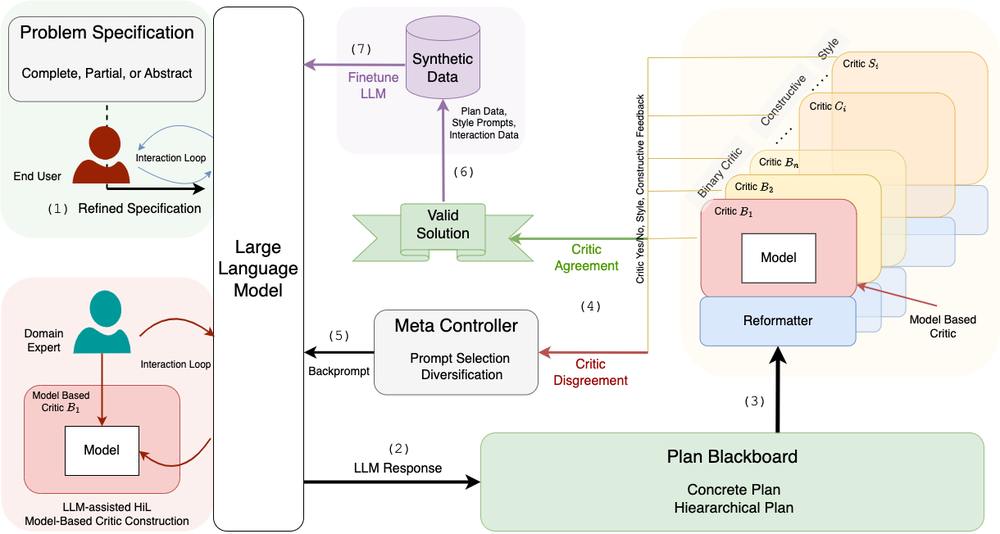

*El marco LLM-Modulo. Figura 3 de Kambhampati et al. (2024), [arXiv:2402.01817](https://arxiv.org/abs/2402.01817), CC BY 4.0.*

* **El LLM propone** un plan candidato.
* **Un banco de críticos lo revisa.** Los **críticos duros** verifican la corrección con modelos formales; por ejemplo, un validador como VAL sobre un modelo PDDL. Los **críticos blandos** revisan estilo o preferencias, y pueden ser otros LLMs.
* **Si todos los críticos duros aprueban**, el plan es una solución válida.
* **Si no, un metacontrolador** reúne las críticas y se las devuelve al LLM para un nuevo intento. Los autores llaman *backprompting* a esa instrucción de vuelta.
* **Las personas** participan una vez por dominio (el experto ayuda a construir los modelos de los críticos) y una vez por problema (precisan la especificación), pero no en el ciclo interno.

La consecuencia central: **la corrección del sistema la heredan los críticos, no el LLM**. Si el LLM nunca propone un buen candidato, el sistema no encuentra solución, pero nunca entrega un plan que los críticos rechacen.

<a id='1-2'></a>
### 1.2 - Qué muestra la evidencia

La evidencia viene sobre todo de **PlanBench** (Valmeekam et al., 2023), un banco de prueba con dominios de la competencia internacional de planificación. El más conocido es **Blocksworld**: apilar bloques en un orden dado. La prueba clave es **Mystery Blocksworld**: el mismo problema, con los nombres de acciones, predicados y objetos cambiados por palabras sin sentido. Para un planificador clásico ambos son idénticos, porque solo mira la estructura. Si un sistema realmente planifica, el cambio de nombres no debería afectarlo.

**En resumen:** los LLMs de 2023 casi nunca resolvían Mystery Blocksworld. Los modelos de razonamiento de 2024, como o1-preview, mejoraron mucho, pero no garantizan planes válidos. Con un verificador externo que devuelve los errores, el acierto sube. Y en 2026 hay modelos de frontera que compiten con planificadores clásicos, aunque todos empeoran con nombres ofuscados.

<details>
<summary><b>Las cifras de cada estudio y cómo leerlas</b> (clic para desplegar)</summary>

| Estudio | Qué se midió | Resultado |
| :--- | :--- | :--- |
| Kambhampati et al. (2024), Tabla 1 | LLMs de 2023–2024 sin ejemplos, 600 instancias por dominio | Blocksworld: entre 0,5 % (Gemini Pro) y 59,3 % (Claude 3 Opus). Mystery Blocksworld: 0,2 % o menos en todos. |
| Kambhampati et al. (2024) | Con VAL como crítico que devuelve los errores | Blocksworld: hasta 82 % en 15 rondas; Logistics: 70 %; Mystery: cerca de 10 %. |
| Valmeekam, Stechly y Kambhampati (2024) | o1-preview, un modelo de razonamiento, en septiembre de 2024 | 97,8 % en Blocksworld y 52,8 % en Mystery (37,3 % con nombres completamente aleatorios). Ningún LLM anterior había superado el 5 % en Mystery. Fast Downward: 100 % en 0,265 s por instancia. |
| Valmeekam, Stechly y Kambhampati (2024) | o1-preview en problemas más difíciles | 23,6 % en problemas de 20 a 40 pasos. Ante problemas imposibles, reconoció que no había solución en el 27 % de los casos y entregó un plan falso en el 54 %. Costo: US$42,12 por cada 100 problemas. |
| Valmeekam et al. (2025) | o1-preview con un verificador externo que devuelve los errores | En Blocksworld difícil, sube de 23,6 % a 98,2 %. |
| Corrêa, Pereira y Seipp (2026) | Modelos de frontera en 360 tareas de 8 dominios de la competencia de 2023, un intento por tarea, validadas con VAL | Gemini 3.1 Pro resolvió 245 tareas, frente a 234 del mejor planificador (Scorpion Maidu); GPT-5, 205. Con nombres ofuscados todos bajan: Gemini 3.1 Pro a 231, GPT-5 a 152 y DeepSeek-R1 de 157 a 93. |


Cómo leer esta evidencia: **algo cambió y algo no**. Los modelos recientes resuelven muchas más tareas, y algunos compiten con planificadores clásicos; esa es la posición contrastante de Corrêa y sus colegas, aceptada en *Communications of the ACM*. Pero ninguno garantiza planes válidos, todos dependen del significado de los nombres y cuestan mucho más que un planificador.

o1-preview es un **modelo de razonamiento**: antes de responder, genera internamente una larga cadena de pasos. Aquí solo interesan sus resultados en planificación; cómo funcionan estos modelos se estudia en la Unidad 3.

</details>

En los dos lados del debate, **solo cuentan como resueltas las tareas cuyo plan pasa el validador**. La pregunta útil para una organización no es «¿planifica el LLM?», sino **«¿qué verifica sus planes?»**.

<details>
<summary><b>Para profundizar: un caso real de diciembre de 2025</b> (clic para desplegar)</summary>

Según NASA y JPL, los días 8 y 10 de diciembre de 2025 el rover Perseverance hizo los primeros recorridos en otro mundo planificados con inteligencia artificial: 210 y 246 metros sobre el borde del cráter Jezero. Modelos visión-lenguaje (los modelos Claude, de Anthropic) analizaron las mismas imágenes que usan los planificadores humanos y generaron los puntos de paso. Antes de enviar los comandos a Marte, el equipo los procesó en el «gemelo digital» del rover y verificó más de 500 000 variables de telemetría. La IA propone; un verificador independiente certifica: es LLM-Modulo fuera del laboratorio (NASA, 2026).

</details>

<a id='1-3'></a>
### 1.3 - El LLM como traductor

Hay otra forma de usar un LLM: no como planificador, sino como **formalizador**. El LLM lee la descripción en lenguaje natural y la traduce a PDDL, y un planificador clásico calcula el plan. Así cada uno hace lo que mejor sabe: el LLM entiende lenguaje y el planificador busca con garantías. Tantakoun, Muise y Zhu (2025) revisan unos 80 trabajos con este enfoque y advierten un riesgo: los LLMs corrigen bien los **errores de sintaxis** (PDDL mal escrito), pero los **errores de significado** siguen siendo un reto. Pueden producir PDDL perfectamente legible que no dice lo que la orden decía.

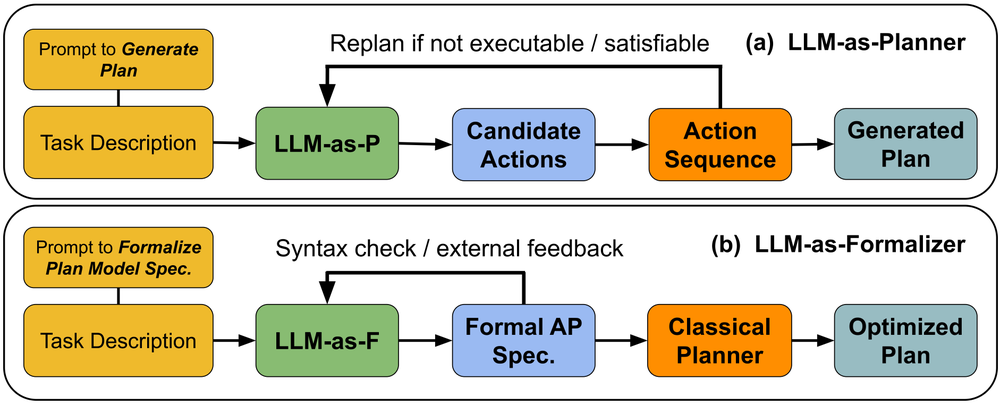

*(a) El LLM planifica; (b) el LLM formaliza y un planificador clásico resuelve. Tantakoun, Muise y Zhu (2025), Findings of ACL, Fig. 1, [ACL Anthology](https://aclanthology.org/2025.findings-acl.1291/), CC BY 4.0.*

<a id='2'></a>
## 2 - El ciclo, sin LLM

Antes de gastar llamadas, vea el mecanismo con un caso fijo.

**Repaso del dominio de MantenIA (Laboratorio 2A).** Tiene cinco acciones: `desplazarse`, `retirar-repuesto`, `bloquear`, `reparar` y `liberar`. Para reparar un equipo, el técnico debe estar en su lugar, estar certificado para ese equipo y llevar un repuesto compatible, y el equipo debe estar bloqueado. Para bloquearlo, el equipo debe estar encendido. **Fast Downward** busca el plan con su configuración por defecto, `lama-first`. El **validador de Unified Planning** comprueba cada paso: aquí cumple el papel de VAL, el validador clásico de PDDL.

<a id='2-1'></a>
### 2.1 - Plan, validador, crítica y plan corregido

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | Un plan de 5 pasos para la OT-512 que omite el bloqueo: es el error típico de saltarse una precondición. |
| **Qué debería pasar** | El validador lo rechaza en el paso 4. El **metacontrolador**, que aquí es la función `e.critica`, convierte el veredicto en una crítica para el LLM. Con la crítica, el plan corregido inserta el bloqueo y el validador lo acepta. |
| **Por qué importa** | Aunque quien propone se equivoque, el sistema completo solo entrega planes que pasaron el validador. |

* Ejecute la siguiente celda para recorrer el ciclo con el plan fijo.

In [ ]:
# Recorrer el ciclo LLM-Modulo con un plan fijo (le falta el bloqueo), sin llamar al LLM
_, _, ot512, _ = e.cargar("ot512")
version_1 = """(desplazarse ana base bodega)
(retirar-repuesto ana sello bodega)
(desplazarse ana bodega planta-norte)
(reparar ana bomba3 sello planta-norte)
(liberar ana bomba3 planta-norte)"""
veredicto_1 = u.validar(ot512, u.plan_desde_texto(ot512, version_1).plan)
p.mostrar_veredicto(veredicto_1, "Versión 1 · veredicto del validador")
p.nota(e.critica(veredicto_1), "aviso", "Crítica que el metacontrolador devolvería al LLM")
version_2 = version_1.replace("(reparar", "(bloquear ana bomba3 planta-norte)\n(reparar")
p.mostrar_veredicto(u.validar(ot512, u.plan_desde_texto(ot512, version_2).plan), "Versión 2 · veredicto del validador")

La crítica está escrita en términos del modelo: qué paso falla y qué hecho le falta. Es el mismo mensaje que el validador da a una persona, reformulado como una instrucción.

<a id='2-2'></a>
### 2.2 - El validador verifica contra el modelo PDDL

En la estrategia 2, el LLM traducirá una orden a PDDL. ¿Qué pasa si la traducción es legible pero dice otra cosa? El archivo `pddl/mantenia_dominio_mal_traducido.pddl` es el dominio de MantenIA al que le falta una sola línea: la precondición `(bloqueado ?e)` de `reparar`, como si un LLM la hubiera omitido al traducir el procedimiento.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | El dominio mal traducido y la OT-512. |
| **Qué debería pasar** | Fast Downward encuentra un plan que **repara la bomba encendida** y la bloquea después, porque `liberar` sí exige el bloqueo. |
| **Cómo falla** | Validado contra el modelo mal traducido, el plan es válido. Validado contra el modelo correcto, falla en el paso 4. |

* Ejecute la siguiente celda para resolver con el dominio mal traducido y validar el plan contra los dos modelos.

In [ ]:
# Resolver con un dominio mal traducido y validar el plan contra los dos modelos
texto_512 = open("pddl/ot512.pddl", encoding="utf-8").read()
mal_traducido = u.leer_problema("pddl/mantenia_dominio_mal_traducido.pddl", texto_512)
plan_mal = u.resolver(mal_traducido)
p.mostrar_plan(plan_mal.pasos, "Plan de Fast Downward con el dominio mal traducido")
p.mostrar_veredicto(u.validar(mal_traducido, plan_mal.plan), "Validado contra el modelo mal traducido")
p.mostrar_veredicto(u.validar(ot512, u.plan_desde_texto(ot512, "\n".join(plan_mal.pasos)).plan),
                    "Validado contra el modelo correcto")

<br>

### Análisis

Es la advertencia más importante del laboratorio: **un planificador correcto y un validador correcto no protegen de un modelo equivocado**. El validador solo sabe lo que el modelo dice. Por eso, cuando un LLM traduce, alguien que conozca el dominio debe revisar el modelo antes de confiar en sus planes. En la estrategia 2, el notebook validará cada plan contra un **modelo de referencia** revisado por personas, no contra la traducción del LLM.

<a id='3'></a>
## 3 - Estrategia 1: el LLM planifica

El LLM recibe el dominio y el problema en PDDL, con una breve guía para leerlo, y debe responder solo con el plan, una acción por línea. Si concluye que no hay plan, debe responder `SIN PLAN`. La función `e.estrategia_1` envía la instrucción, lee la respuesta con `u.plan_desde_texto` y la juzga con el validador. Clasifica cada fallo así:

| Clasificación | Qué significa |
| :--- | :--- |
| **precondición incumplida** | Un paso no se puede aplicar en el estado en que está. |
| **meta no alcanzada** | Todas las acciones se pueden aplicar, pero al final no se cumple la meta. |
| **acción u objeto inexistente** | El plan usa una acción, un objeto o un número de argumentos que el modelo no tiene. |
| **formato ilegible** | No se encontraron acciones en la respuesta, o alguna línea del plan no tiene el formato de una acción. |
| **inventa un plan / dice que no hay plan** | Para un problema sin solución, propone un plan; o, para uno con solución, afirma que no la hay. |

Si la respuesta trae explicaciones además del plan, `u.plan_desde_texto` lee el último bloque de líneas que son solo acciones y deja una nota de **formato** en el «Detalle». El plan se juzga igual, pero el LLM no siguió la instrucción de responder solo con el plan.

En clase se prueban dos órdenes: la OT-512 (6 pasos) y la OT-518 (12 pasos). En casa, en la sección 7, se agregan las demás.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | Dominio y problema PDDL de la OT-512 y de la OT-518. |
| **Qué debería pasar** | Un plan válido para cada orden. |
| **Cómo puede fallar** | Omitir una precondición (por ejemplo, el bloqueo), asignar a un técnico no certificado, inventar nombres, escribir mal una acción o perder el hilo en el plan más largo. |

* Ejecute la siguiente celda para aplicar la estrategia 1 a las dos órdenes. Despliegue «Conversación con el LLM» para leer la instrucción exacta y la respuesta.

In [ ]:
# Estrategia 1: el LLM planifica directamente (OT-512 y OT-518)
resultados_clase = []
for clave in ["ot512", "ot518"]:
    resultado = e.estrategia_1(llm, clave)
    resultados_clase.append(resultado)
    e.mostrar_resultado(resultado)

<br>

### Análisis

Los resultados de un LLM **varían**: entre modelos, entre proveedores y, en muchos modelos, entre una corrida y otra. Por eso este análisis no le dice qué obtuvo; le dice cómo leerlo.

* **Si el plan es válido**, el LLM acertó en esta instancia. Pero solo lo sabe porque el validador lo comprobó: sin validador, un plan válido y uno inválido se ven igual de convincentes.
* **Si falla por una precondición**, lea cuál. Omitir el bloqueo, o asignar la bomba 3 a Luis, que no está certificado para ella, son errores de *interacción*: el LLM conoce las acciones, pero no comprobó sus condiciones en orden. Es la diferencia entre **saber de planes** y **producir un plan ejecutable**.
* **Si usa nombres o argumentos que no existen**, el error es de formato, pero igual de grave: ese plan fallaría al ejecutarse. Con más pasos y más objetos, como en la OT-518, aumentan las oportunidades de error.

<a id='4'></a>
## 4 - Estrategia 2: el LLM traduce y Fast Downward resuelve

Ahora el LLM no planifica: **traduce**. Recibe el dominio y la orden de trabajo escrita, tal como la abre el sistema de mantenimiento, y debe producir el problema PDDL: los objetos, el estado inicial y la meta. Luego:

1. Si el PDDL no se puede leer, el error vuelve al LLM como crítica, con hasta 2 reintentos. Es el error de **sintaxis** que, según la literatura, los LLMs corrigen bien.
2. Fast Downward resuelve el problema traducido.
3. El plan se valida **contra el problema de referencia**, no contra la traducción. Así se detectan los errores de **significado**: el «Detalle» lista los hechos traducidos que faltan o sobran.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | Dominio PDDL y orden escrita de la OT-512 y de la OT-518 (archivos de la carpeta `ordenes/`). |
| **Qué debería pasar** | Una traducción idéntica a la referencia y, con ella, un plan válido de Fast Downward. |
| **Cómo puede fallar** | PDDL ilegible (sintaxis). O PDDL legible que omite o inventa hechos (significado): por ejemplo, olvidar que el equipo sigue encendido, o declarar una certificación que la orden no da. |

* Ejecute la siguiente celda para ver una de las órdenes escritas y aplicar la estrategia 2 a las dos órdenes.

In [ ]:
# Estrategia 2: el LLM traduce la orden escrita a PDDL y Fast Downward resuelve
p.mostrar_archivo("ordenes/ot518.md", "Orden escrita de la OT-518 (lo que recibe el LLM)")
for clave in ["ot512", "ot518"]:
    resultado = e.estrategia_2(llm, clave)
    resultados_clase.append(resultado)
    e.mostrar_resultado(resultado)

<br>

### Análisis

* **Si la traducción es idéntica a la referencia**, el plan de Fast Downward es válido *con garantía*: la búsqueda y la verificación las hizo el planificador, y el LLM solo aportó la comprensión del lenguaje.
* **Si el PDDL es ilegible**, mire si los reintentos lo corrigieron: los errores de sintaxis son los más fáciles de detectar, porque el lector de PDDL los señala.
* **Si el plan es inválido en la orden real**, o si la traducción no tiene solución pero la orden sí, lea el «Detalle». Es un **error de significado**, el riesgo que advierten Tantakoun et al. (2025): Fast Downward resolvió perfectamente el problema equivocado, como en la sección 2.2.
* **En una organización real no habría modelo de referencia** para cada orden. Según LLM-Modulo, las personas participan una vez por problema: aquí, alguien tendría que revisar el estado inicial que tradujo el LLM.

<a id='5'></a>
## 5 - Estrategia 3: generar y verificar

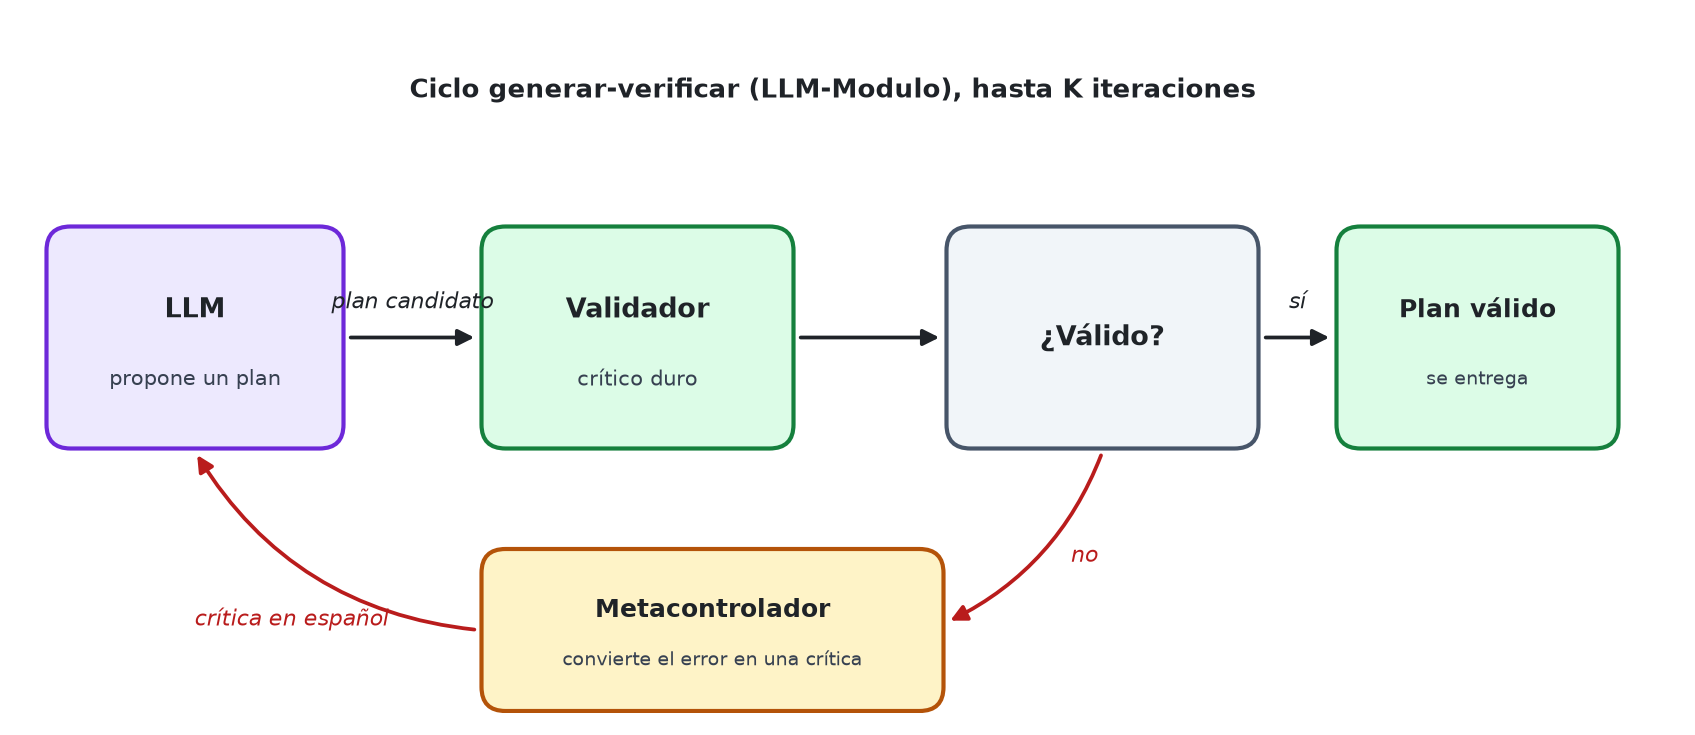

La estrategia 3 es el marco LLM-Modulo completo, con un solo crítico duro: el validador.

1. El LLM propone un plan (con la misma instrucción de la estrategia 1).
2. Si el validador lo acepta, termina.
3. Si no, el metacontrolador (`e.critica`) devuelve al LLM la crítica en español: qué paso falla y qué hecho le falta.
4. Se repite hasta **K = 5** iteraciones. Cada iteración es una llamada nueva, que incluye toda la conversación anterior.

Si el LLM responde `SIN PLAN`, el ciclo termina: un validador revisa **planes**, no la afirmación «no hay plan». Para comprobarla hace falta un planificador que lo demuestre, como en la variante c) del Laboratorio 2A, donde Fast Downward demostró que la OT-512 sin técnico certificado no tiene solución.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | Dominio y problema PDDL de la OT-512 y de la OT-518, y las críticas del validador. |
| **Qué debería pasar** | Un plan válido, quizá después de algunas iteraciones. |
| **Cómo puede fallar** | El LLM no logra corregir el plan en 5 iteraciones, corrige un error e introduce otro, o se rinde y afirma que no hay plan. |

* Ejecute la siguiente celda para aplicar la estrategia 3 a las dos órdenes. Si hubo críticas, despliegue la conversación para leerlas, en rojo, y ver cómo responde el LLM a cada una. Si el plan fue válido en la primera iteración, no hay críticas: la estrategia 3 se comporta igual que la 1.

In [ ]:
# Estrategia 3: ciclo generar-verificar con hasta K = 5 iteraciones (OT-512 y OT-518)
K = 5
for clave in ["ot512", "ot518"]:
    resultado = e.estrategia_3(llm, clave, K=K)
    resultados_clase.append(resultado)
    e.mostrar_resultado(resultado)

<br>

### Análisis

* **Si fue válido en la primera iteración**, el validador solo confirmó el plan: la estrategia 3 costó lo mismo que la 1, y su plan tiene la garantía del validador.
* **Si llegó a un plan válido después de una o más críticas**, observe el patrón LLM-Modulo: el LLM no se verificó a sí mismo, lo corrigió un crítico externo. El plan entregado es correcto según el modelo porque pasó el validador, no porque el LLM sea confiable.
* **Si no llegó en 5 iteraciones**, o si se rindió, mire la conversación: ¿corrigió el paso criticado?, ¿introdujo otro error? En Mystery Blocksworld, los autores del marco vieron lo mismo: el sistema rara vez encuentra solución, pero nunca entrega una incorrecta.
* **Cuente el costo.** Cada iteración reenvía la conversación completa, así que los tokens de entrada crecen con cada vuelta.

<a id='6'></a>
## 6 - Primera comparación

Junte los resultados de clase y agregue, como referencia, a **Fast Downward** sobre los mismos problemas.

* Ejecute la siguiente celda para ver la tabla comparativa.

In [ ]:
# Tabla comparativa de clase, con Fast Downward como referencia clásica
referencia = [e.fast_downward(clave) for clave in ["ot512", "ot518"]]
e.tabla(resultados_clase + referencia)
print("Consumo del LLM hasta ahora:", llm.texto_resumen())

Lea la tabla por columnas: ¿qué estrategias dieron resultados correctos?, ¿cuántas iteraciones y tokens costaron?, ¿cuánto tardaron frente a Fast Downward? Las conclusiones quedan para la sección 8, cuando tenga el experimento completo.

---

### ⏸ Hasta aquí, el trabajo en clase

Las secciones 7 a 9 se trabajan en casa: cerca de una hora.

---

<a id='7'></a>
## 7 - Experimento completo

En casa se agregan tres instancias más:

| Instancia | Qué pone a prueba |
| :--- | :--- |
| **OT-530** · 3 técnicos, 3 equipos, 16 pasos | El tamaño: un plan más largo, con más objetos y más interacciones. |
| **OT-512 sin técnico certificado** | La honestidad: el problema no tiene solución. Lo correcto es decir `SIN PLAN` o, en la estrategia 2, que el planificador lo demuestre. |
| **OT-512 «misterio»** | La comprensión de la estructura: la misma OT-512 con todos los nombres ofuscados, como en Mystery Blocksworld. |

La versión misterio se aplica a las estrategias 1 y 3. No se aplica a la 2: para traducir, el LLM necesitaría una orden escrita que relacione las palabras sin sentido con su significado, y eso desharía la ofuscación.

* Antes de ejecutar, escriba en la celda ✏️ siguiente los apellidos de la pareja; quedan registrados en el CSV. Si quiere observar la variabilidad del LLM, ponga `REPETICIONES = 2` o `3`. Las repeticiones necesitan un LLM real: con respuestas grabadas solo existe la primera.

In [ ]:
# ✏️ Identificación de la pareja y repeticiones (las repeticiones necesitan un LLM real)
PAREJA = "apellido1-apellido2"
REPETICIONES = 1

La siguiente celda corre todas las combinaciones. Reutiliza los resultados de clase de la OT-512 y la OT-518 para no pagar dos veces las mismas llamadas, y agrega a Fast Downward como referencia. Con la API tarda unos minutos; con un modelo local en un portátil, puede tardar más de media hora.

* Ejecute la siguiente celda para correr el experimento completo.

In [ ]:
# Experimento completo: todas las instancias con las estrategias que les aplican, más Fast Downward
plan_experimento = {"ot512": ["e1", "e2", "e3"], "ot518": ["e1", "e2", "e3"], "ot530": ["e1", "e2", "e3"],
                    "ot512_sin_solucion": ["e1", "e2", "e3"], "ot512_misterio": ["e1", "e3"]}
ya_hechos = {(r.estrategia, r.instancia): r for r in resultados_clase}
resultados = []
for clave, estrategias in plan_experimento.items():
    for est in estrategias:
        for rep in range(1, REPETICIONES + 1):
            if rep == 1 and (est, clave) in ya_hechos:
                resultados.append(ya_hechos[(est, clave)])
                continue
            resultado = e.ESTRATEGIAS[est](llm, clave, repeticion=rep)
            resultados.append(resultado)
            marca = ("✓" if resultado.correcto else "✗") if resultado.disponible else "—"
            print(f"{e.INSTANCIAS[clave]['titulo']:42} {e.NOMBRES[est]:46} {marca} {resultado.resultado}")
    resultados.append(e.fast_downward(clave))
e.tabla(resultados)
print("Consumo total del LLM:", llm.texto_resumen())

Ahora el resumen gráfico por estrategia: cuántos resultados fueron correctos, cuánto tardó cada estrategia por instancia y cuántos tokens consumió.

* Ejecute la siguiente celda para ver el gráfico y exportar los resultados a `resultados_2B.csv`.

In [ ]:
# Gráfico comparativo y exportación de los resultados al CSV común del curso
e.grafico(resultados)
ruta = e.exportar_csv(resultados, pareja=PAREJA)
p.nota(f"Resultados exportados a {ruta}. Este archivo se entrega junto con el notebook.", "exito")

La tabla abrevia el «Detalle» y no muestra las conversaciones. Para el análisis, conviene leer completos los casos que más enseñan: los fallos, los que necesitaron más de una iteración y los que tienen notas de formato o diferencias en la traducción.

* Ejecute la siguiente celda para ver esos casos, con su plan y su conversación.

In [ ]:
# Ver completos los casos que más enseñan: fallos, varias iteraciones, notas de formato o diferencias
e.detalles(resultados)

Ahora que el experimento terminó, puede ver la clave de la versión misterio en `pddl/misterio_clave.md`. Compare el resultado del LLM en la OT-512 con su resultado en la versión misterio: la estructura es idéntica y solo cambian los nombres.

> **Nota sobre el CSV:** en las sesiones 3 a 7, cada técnica clásica tiene un laboratorio de **contrapunto LLM**: la misma tarea resuelta con un LLM, para comparar. Todos producen un CSV con el mismo esquema, y `resultados_2B.csv` es el primero. Sus columnas son la sesión, el laboratorio, la pareja, la instancia, el método (`clasico`, `llm` o `hibrido`), la estrategia, el proveedor y el modelo, si el resultado fue correcto, las iteraciones, las llamadas, los tokens, el costo y el tiempo. En la sesión 8 se analizan juntos.

<a id='8'></a>
## 8 - Su análisis

* Escriba en la celda siguiente el análisis de la pareja, de 300 a 500 palabras, con base en **sus** resultados. No hace falta responder pregunta por pregunta; úselas como guía:
    * **Validez.** ¿Qué estrategia dio más resultados correctos? ¿Qué tipos de error aparecieron en cada una?
    * **Iteraciones.** En la estrategia 3, ¿cuántas críticas necesitó el LLM? ¿Las críticas ayudaron siempre? Si en su corrida no hubo ninguna crítica, dígalo y explique qué significa; para ver el ciclo de críticas con un LLM real, use la sección 9.1, que con respuestas grabadas reproduce una corrida de un LLM más pequeño.
    * **Tamaño, problemas imposibles y nombres.** ¿Qué pasó con la OT-530? ¿El LLM reconoció la orden sin solución o inventó un plan? ¿Cambió el resultado en la versión misterio?
    * **Costo.** Compare tokens, tiempo y costo con Fast Downward. ¿Qué paga una organización por usar el LLM, y qué recibe a cambio?
    * **Recomendación.** Si MantenIA tuviera que elegir una de las tres estrategias para su sistema de órdenes, ¿cuál recomendarían y con qué verificador al lado?

**✏️ Análisis de la pareja (sección 8).** *Escriba aquí su análisis.*

<a id='9'></a>
## 9 - Inténtelo usted mismo, entrega y criterios

<a id='9-1'></a>
### 9.1 - Inténtelo usted mismo

Esta sección es **opcional**. Con una clave de API o el modelo local, hace llamadas nuevas. Con respuestas grabadas, reproduce una corrida real de un LLM más pequeño, `qwen3:4b-instruct` (el modelo local del curso), con la estrategia 3: un caso en el que se ve el ciclo de críticas en acción. Algunas ideas:

* **Otro LLM.** Compare otro LLM sobre las mismas instancias: por ejemplo, `claude-sonnet-5-5`, más capaz y más costoso que Haiku (`OTRO_LLM`), o el modelo local frente a la API (`OTRO_PROVEEDOR = "ollama"`). Cada fila del CSV registra el LLM, así que los resultados se pueden juntar.
* **Más iteraciones.** Suba `K` a 8 en la estrategia 3 y observe si el LLM sigue mejorando o se estanca.
* **Su propio dominio.** Si escribió en PDDL el problema del trabajo independiente TI-1 (las acciones de un proceso de su organización), póngalo a prueba con la estrategia 3. Primero regístrelo como una instancia más:

```python
e.INSTANCIAS["mio"] = {"titulo": "Mi proceso", "dominio": "mi_dominio.pddl",
                       "problema": "mi_problema.pddl", "orden": None}
e.mostrar_resultado(e.estrategia_3(llm, "mio", K=5))
```

* Complete la celda siguiente con el proveedor, el LLM y el número de iteraciones que quiera probar, y ejecútela. Despliegue cada conversación para leer las críticas.

In [ ]:
# ✏️ Opcional: la estrategia 3 con otro LLM o con más iteraciones
OTRO_PROVEEDOR = None   # None: el mismo de la sección 0.1; por ejemplo "ollama" para el modelo local
OTRO_LLM = None         # por ejemplo "claude-sonnet-5-5"; None: el mismo LLM, o el de ese proveedor por defecto
K_NUEVO = 8
if llm.proveedor == "grabado" and OTRO_PROVEEDOR is None:
    # Con respuestas grabadas: una corrida real de qwen3:4b-instruct, un LLM más pequeño, con la estrategia 3
    otro = cliente_llm.ClienteLLM(proveedor="grabado", carpeta_grabaciones="grabaciones/qwen3-4b-instruct")
else:
    otro = cliente_llm.ClienteLLM(proveedor=OTRO_PROVEEDOR or llm.proveedor, grabar=False,
                                  modelo=OTRO_LLM or (None if OTRO_PROVEEDOR else llm.modelo))
for clave in ["ot530", "ot512_misterio"]:
    e.mostrar_resultado(e.estrategia_3(otro, clave, K=K_NUEVO))

<a id='9-2'></a>
### 9.2 - Entrega y criterios de evaluación

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_2B.csv`. Uno por pareja, por el canal del curso, al inicio de la semana 2 del curso. No entregue su archivo `.env`.

**Resultados reproducibles.** Con la API, cada corrida puede dar resultados distintos. Por eso, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) **antes** de escribir el análisis, y escríbalo sobre esas salidas. Si después vuelve a ejecutar con la API, revise que el análisis y el CSV sigan coincidiendo con lo que muestra el notebook.

| Criterio | Peso |
| :--- | :--- |
| Experimento completo: las 14 combinaciones de estrategia e instancia (la estrategia 2 no se aplica a la versión misterio), con salidas que coinciden con el CSV y con el análisis | 30 % |
| Interpretación correcta de los veredictos del validador y de los tipos de error | 30 % |
| Comparación y recomendación argumentada, con validez, iteraciones y costo | 30 % |
| `resultados_2B.csv` completo, con el esquema común | 10 % |

### ✏️ Declaración de uso de asistentes de IA

En este laboratorio el LLM es el objeto de estudio. Aquí se declara solo el uso **adicional**: por ejemplo, si consultaron a un asistente para interpretar resultados o redactar el análisis.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted completó el laboratorio y puso a prueba, con sus propios datos, la tesis del club de lectura.

En la estrategia 1 vio al LLM planificar solo. Puede acertar, sobre todo en órdenes pequeñas; cuando falla, el error suele ser de interacción entre acciones (una precondición que no comprobó) o de formato. Y nada en el texto de la respuesta distingue un plan correcto de uno incorrecto. En la estrategia 2 lo vio traducir: cuando la traducción es fiel, la garantía la pone el planificador; cuando no lo es, el sistema resuelve con toda corrección el problema equivocado. Por eso el modelo también se revisa. En la estrategia 3 vio el marco LLM-Modulo completo: el LLM propone, el validador critica y el ciclo solo entrega planes que pasaron el validador. Y en todas, el costo: segundos y miles de tokens frente a las décimas de segundo de Fast Downward.

La idea que une todo es la de la unidad: **quien genera no es quien certifica**. Ese principio conecta con lo que sigue:

* En el **Laboratorio 2C**, el plan será un plan.md en lenguaje natural. No hay modelo formal contra el cual validarlo: verifican una persona y las comprobaciones que el propio plan declara en cada paso.
* En el **trabajo independiente TI-2** de esta sesión, verificará a mano el plan de un LLM para su propio proceso, con nombres normales y ofuscados.
* En la **sesión 8**, los resultados de su CSV se juntarán con los de los demás laboratorios de contrapunto del curso.

<a id='referencias'></a>
## Referencias

* Kambhampati, S., Valmeekam, K., Guan, L., Verma, M., Stechly, K., Bhambri, S., Saldyt, L. y Murthy, A. (2024). Position: LLMs can't plan, but can help planning in LLM-Modulo frameworks. *ICML 2024*, PMLR 235. [PMLR](https://proceedings.mlr.press/v235/kambhampati24a.html) · [arXiv (CC BY 4.0)](https://arxiv.org/abs/2402.01817)
* Valmeekam, K., Marquez, M., Olmo, A., Sreedharan, S. y Kambhampati, S. (2023). PlanBench: An extensible benchmark for evaluating large language models on planning and reasoning about change. *NeurIPS 2023, Datasets and Benchmarks*. [arXiv](https://arxiv.org/abs/2206.10498)
* Valmeekam, K., Stechly, K. y Kambhampati, S. (2024). LLMs still can't plan; can LRMs? A preliminary evaluation of OpenAI's o1 on PlanBench. [arXiv:2409.13373](https://arxiv.org/abs/2409.13373)
* Valmeekam, K., Stechly, K., Gundawar, A. y Kambhampati, S. (2025). A systematic evaluation of the planning and scheduling abilities of the reasoning model o1. *Transactions on Machine Learning Research*. [OpenReview](https://openreview.net/forum?id=FkKBxp0FhR) · [arXiv:2410.02162](https://arxiv.org/abs/2410.02162)
* Corrêa, A. B., Pereira, A. G. y Seipp, J. (2026). Frontier large language models are becoming competitive with state-of-the-art planners. *Communications of the ACM*, en prensa. [Ficha de los autores](https://mrlab.ai/papers/correa-et-al-cacm2026.html) · [arXiv:2511.09378](https://arxiv.org/abs/2511.09378)
* Tantakoun, M., Muise, C. y Zhu, X. (2025). LLMs as planning formalizers: A survey for leveraging large language models to construct automated planning models. *Findings of ACL 2025*, 25167–25188. [ACL Anthology](https://aclanthology.org/2025.findings-acl.1291/)
* Howey, R., Long, D. y Fox, M. (2004). VAL: Automatic plan validation, continuous effects and mixed initiative planning using PDDL. *ICTAI 2004*, 294–301. [Manuscrito](https://strathprints.strath.ac.uk/2550/6/strathprints002550.pdf)
* Helmert, M. (2006). The Fast Downward planning system. *JAIR*, 26, 191–246. [JAIR](https://www.jair.org/index.php/jair/article/view/10457)
* NASA (2026, 30 de enero). NASA's Perseverance rover completes first AI-planned drive on Mars. [Nota oficial](https://www.nasa.gov/missions/mars-2020-perseverance/perseverance-rover/nasas-perseverance-rover-completes-first-ai-planned-drive-on-mars/)
* Precios de las API, consultados el 21 de octubre de 2026: [Anthropic](https://platform.claude.com/docs/en/about-claude/pricing) · [OpenAI](https://developers.openai.com/api/docs/pricing) · [Google Gemini](https://ai.google.dev/gemini-api/docs/pricing)